# Tasks 1–2: original implementations + **LiteMedSAM** execution

**The segmentation model run in THIS notebook is LiteMedSAM, not the larger MedSAM.** It uses the original `CVPR24_LiteMedSAM_infer.py`, `TinyViT` encoder, `MedSAM_Lite` wrapper and official `lite_medsam.pth` weights. The folder/repository may still be named MedSAM because LiteMedSAM is a branch of that repository.

This notebook implements Task 1 for both repositories and Task 2 for LiteMedSAM. It does not run MedNet classification, training or integration.

Your forks:
- https://github.com/KrishnachaithanyaThummala/MedSAM/tree/LiteMedSAM
- https://github.com/KrishnachaithanyaThummala/MedNet

For Colab: **Runtime → Change runtime type → GPU**, save, connect, then run cells in order. GPU is used when available; otherwise the notebook explicitly reports CPU fallback. GPU inference must never be inferred just from a GPU runtime selection.

## Understand the two segmentation models before running

| Property | MedSAM (`main`) | LiteMedSAM (`LiteMedSAM` branch, used here) |
|---|---|---|
| Purpose | Prompt-guided medical segmentation | Lightweight prompt-guided medical segmentation |
| Image encoder | Larger ViT-B for the standard MedSAM example | TinyViT |
| Main example entry point | `MedSAM_Inference.py` | `CVPR24_LiteMedSAM_infer.py` |
| Checkpoint for that example | `medsam_vit_b.pth` | `lite_medsam.pth` |
| Image preparation in these inference paths | 1024×1024 in the standard demo | Longest side 256; normalize; bottom/right pad to 256×256 |
| Prompt/mask components | SAM prompt encoder and mask decoder | SAM prompt encoder and mask decoder configured for the lightweight pipeline |

Both use **image encoder + prompt encoder → mask decoder**. The encoders process separate inputs. A box says which region to segment; the mask is the pixel-level output. LiteMedSAM's README describes distilling a lighter encoder from MedSAM, followed by segmentation fine-tuning. We load pretrained weights, not train from scratch. Do not interchange the two checkpoints.

No speed ratio or clinical accuracy is measured here.

## 1. Runtime, GPU and error-recording setup

In [1]:
import sys, os, json, platform, subprocess, traceback, hashlib, time
from pathlib import Path
from contextlib import contextmanager
import torch
ROOT = Path(os.environ.get("LITEMEDSAM_TASKS12_ROOT", "/content/LiteMedSAM_Tasks12" if Path("/content").exists() else str(Path.cwd()/"outputs/tasks12_local")))
ROOT.mkdir(parents=True, exist_ok=True)
LOGS = ROOT/"logs"; LOGS.mkdir(exist_ok=True)
@contextmanager
def stage(name):
    try:
        yield
        with (LOGS/"stages.jsonl").open("a") as f: f.write(json.dumps({"stage":name,"status":"passed"})+"\n")
    except Exception:
        error=traceback.format_exc()
        (LOGS/(name+"_error.txt")).write_text(error)
        with (LOGS/"stages.jsonl").open("a") as f: f.write(json.dumps({"stage":name,"status":"failed","traceback":error})+"\n")
        raise

def command(args, cwd=None, log="command"):
    result=subprocess.run(args,cwd=cwd,text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT)
    (LOGS/(log+".txt")).write_text(result.stdout)
    print(result.stdout[-6000:])
    result.check_returncode()
    return result

DEVICE="cuda:0" if torch.cuda.is_available() else "cpu"
runtime={"python":sys.version,"torch":torch.__version__,"cuda_build":torch.version.cuda,"device":DEVICE,
         "gpu":torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}
print(json.dumps(runtime,indent=2))
if DEVICE=="cpu": print("CPU FALLBACK: no CUDA GPU is available in this session.")
else:
    assert (torch.ones(1,device=DEVICE)+1).item()==2
    command(["nvidia-smi"],log="gpu")
(LOGS/"runtime.json").write_text(json.dumps(runtime,indent=2))


{
  "python": "3.12.14 (main, Aug 25 2026, 13:50:33) [Clang 22.1.3 ]",
  "torch": "2.6.0",
  "cuda_build": null,
  "device": "cpu",
  "gpu": null
}
CPU FALLBACK: no CUDA GPU is available in this session.


147

**Result/inference:** Read the printed device. CUDA tensor success establishes that the session can execute GPU operations; LiteMedSAM itself is checked below. Errors from subsequent stages are saved before being raised.

## 2. Task 1 — clone BOTH forks and verify against the original repositories

In [2]:
SOURCES={
 "LiteMedSAM":{"original":"https://github.com/bowang-lab/MedSAM.git","fork":"https://github.com/KrishnachaithanyaThummala/MedSAM.git","branch":"LiteMedSAM","commit":"b0fab476e54e631dd412b25e0db9fdf2a2b0f54c"},
 "MedNet":{"original":"https://github.com/Md-Ferdous/MedNet.git","fork":"https://github.com/KrishnachaithanyaThummala/MedNet.git","branch":"main","commit":"6adb072630811b1d39568a87732aed96dc39c9ae"}}
with stage("clone_and_verify"):
    for name,record in SOURCES.items():
        repo=ROOT/name
        if not repo.exists(): command(["git","clone","--branch",record["branch"],"--single-branch",record["fork"],str(repo)],log=name+"_clone")
        command(["git","checkout","--detach",record["commit"]],cwd=repo,log=name+"_checkout")
        actual=subprocess.check_output(["git","rev-parse","HEAD"],cwd=repo,text=True).strip()
        assert actual==record["commit"]
        # Verify that this exact commit is also present in the named original source.
        command(["git","fetch",record["original"],record["commit"]],cwd=repo,log=name+"_verify_original")
        fetched=subprocess.check_output(["git","rev-parse","FETCH_HEAD"],cwd=repo,text=True).strip()
        assert fetched==actual
        assert not subprocess.check_output(["git","status","--porcelain","--untracked-files=no"],cwd=repo,text=True).strip(), "Tracked original files were modified."
        record["checked_out_commit"]=actual
        print(name,"branch of origin:",record["branch"],"pinned commit:",actual)
    (LOGS/"sources.json").write_text(json.dumps(SOURCES,indent=2))
LITE=ROOT/"LiteMedSAM"; MEDNET=ROOT/"MedNet"


HEAD is now at b0fab47 Update README.md



From https://github.com/bowang-lab/MedSAM
 * branch            b0fab476e54e631dd412b25e0db9fdf2a2b0f54c -> FETCH_HEAD

LiteMedSAM branch of origin: LiteMedSAM pinned commit: b0fab476e54e631dd412b25e0db9fdf2a2b0f54c
HEAD is now at 6adb072 Initialize README.md with project details



From https://github.com/Md-Ferdous/MedNet
 * branch            6adb072630811b1d39568a87732aed96dc39c9ae -> FETCH_HEAD

MedNet branch of origin: main pinned commit: 6adb072630811b1d39568a87732aed96dc39c9ae


**Result/inference:** Both repositories must exist locally and both original-source commit checks must pass. Detached HEAD is intentional: the run is pinned to a known revision. A fork URL alone does not identify which branch/model was executed.

## Task 1 — model, demo, dependency and checkpoint inventory

| Repository | Definitions / major files | Demo and dependencies | Checkpoints |
|---|---|---|---|
| LiteMedSAM | `tiny_vit_sam.py`; `MedSAM_Lite` in `CVPR24_LiteMedSAM_infer.py`; prompt encoder, mask decoder and transformer in `segment_anything/modeling/` | README + `test_demo/readme.md` link official demo data. `setup.py` lists full dependencies; this notebook installs the inference subset. | Official README/work_dir links provide `lite_medsam.pth`; downloaded separately below. |
| MedNet | `MedNet.py`: `Darma`, `ResidualCBAMBackbone`, residual/separable-convolution and attention classes. `preprocessing.py` exports BloodMNIST images; it is not a generic ultrasound tool. | README gives examples, but its `MedNet` class name differs from actual `Darma`. Source imports include torch/torchvision, numpy, OpenCV, timm, albumentations, tensorboard, sklearn, tqdm and matplotlib. | No trained checkpoint file is bundled in the inspected Git tree. The source training code saves `.pt` weights; the Task 3 architecture test uses untrained weights unless a suitable checkpoint is separately supplied. |

MedNet source returns `(scores, activations)`. Its classification execution is deliberately outside Tasks 1–2. Reading its source does not require installing all of its training dependencies.

In [3]:
import ast
with stage("inventory"):
    inventory={}
    for name,repo in [("LiteMedSAM",LITE),("MedNet",MEDNET)]:
        tracked=subprocess.check_output(["git","ls-tree","-r","--name-only","HEAD"],cwd=repo,text=True).splitlines()
        inventory[name]={"tracked_files":tracked,"bundled_weight_files":[p for p in tracked if p.endswith((".pth",".pt",".ckpt"))]}
        print(name,"tracked files:",len(tracked),"bundled weights:",inventory[name]["bundled_weight_files"])
    tree=ast.parse((MEDNET/"MedNet.py").read_text())
    inventory["MedNet"]["classes"]=[node.name for node in tree.body if isinstance(node,ast.ClassDef)]
    assert "Darma" in inventory["MedNet"]["classes"]
    print("Actual MedNet classes:",inventory["MedNet"]["classes"])
    print("LiteMedSAM full dependency declaration:\n",(LITE/"setup.py").read_text())
    (LOGS/"inventory.json").write_text(json.dumps(inventory,indent=2))


LiteMedSAM tracked files: 53 bundled weights: []
MedNet tracked files: 3 bundled weights: []
Actual MedNet classes: ['AlbumentationsTransform', 'FocalLoss', 'ChannelAttention', 'SpatialAttention', 'CBAM', 'DepthwiseSeparableConv', 'ResidualDSCBAMBlock', 'ResidualCBAMBackbone', 'Darma', 'EarlyStopping']
LiteMedSAM full dependency declaration:
 # Copyright (c) Meta Platforms, Inc. and affiliates.
# All rights reserved.

# This source code is licensed under the license found in the
# LICENSE file in the root directory of this source tree.
# Adapted from https://github.com/facebookresearch/segment-anything

from setuptools import find_packages, setup

setup(
    name="litemedsam",
    version="0.0.1",
    author="Jun Ma",
    python_requires=">=3.9",
    install_requires=["monai", "timm", "matplotlib", "scikit-image", "SimpleITK>=2.2.1", "pyarrow", "pandas", "nibabel", "tqdm", "scipy", "ipympl", "opencv-python", "jupyterlab", "ipywidgets"],
    packages=find_packages(exclude="notebooks"),


**Result/inference:** The actual Git tree and AST inventory establish what is present, rather than assuming files from the README. An absent bundled checkpoint does not prove that no weights exist anywhere outside this repository.

## Exactly which folders/files execute LiteMedSAM here?

**Direct execution/computation path**

| File/folder | Role in this run |
|---|---|
| `CVPR24_LiteMedSAM_infer.py` | The original script we execute. Defines the `MedSAM_Lite` container, builds components, loads weights, preprocesses input, handles supplied boxes and saves masks. |
| `tiny_vit_sam.py` | TinyViT image encoder. This is the clearest distinction from the larger MedSAM image-encoder path. |
| `segment_anything/modeling/prompt_encoder.py` | Converts the supplied box into prompt embeddings. |
| `segment_anything/modeling/mask_decoder.py` | Predicts mask logits using image/prompt embeddings. |
| `segment_anything/modeling/transformer.py` | Two-way attention used by the decoder. |
| `segment_anything/modeling/common.py` | Shared layers used by the components. |
| `work_dir/LiteMedSAM/lite_medsam.pth` | Learned LiteMedSAM weights. Downloaded file, not Python code. |
| `ROOT/demo_input/2DBox_US_demo.npz` | Authors' RGB ultrasound image and supplied box, downloaded separately. |
| `ROOT/results/` | Generated mask NPZ/PNG, original image, plot and timing; `ROOT/logs/` contains versions and errors. |

**Imported indirectly, but not used as this run's inference interface:** package `__init__.py` files can import `build_sam.py`, `predictor.py`, `automatic_mask_generator.py`, `modeling/sam.py`, `modeling/image_encoder.py`, and supporting `utils` modules. Their import does not mean we selected the ViT image encoder or automatic mask generation. The executed script explicitly constructs **TinyViT** and invokes its components directly.

**Not run:** `MedSAM_Inference.py` from the `main` branch, training/distillation scripts, root dataset-preprocessing utilities, comparisons, optional prompting extensions, and MedNet classification. Some of these folders exist on `main` and are absent from the LiteMedSAM branch.

## 3. Install and verify the LiteMedSAM inference dependencies

In [4]:
with stage("dependencies"):
    # Preserve the runtime's matched torch/torchvision/CUDA installation.
    command([sys.executable,"-m","pip","install","timm==0.9.12","gdown==5.2.0",
             "opencv-python-headless==4.10.0.84","numpy","matplotlib","pandas","tqdm"],log="pip_install")
    command([sys.executable,"-c","import torch, torchvision, timm, cv2, pandas, matplotlib; from tiny_vit_sam import TinyViT; from segment_anything.modeling import PromptEncoder, MaskDecoder, TwoWayTransformer; print('LiteMedSAM component imports passed')"],cwd=LITE,log="imports")
    versions=subprocess.check_output([sys.executable,"-m","pip","freeze"],text=True)
    (LOGS/"package_versions.txt").write_text(versions)
    print("Full installed package versions saved to",LOGS/"package_versions.txt")


n-headless==4.10.0.84
  Using cached opencv_python_headless-4.10.0.84-cp37-abi3-macosx_11_0_arm64.whl.metadata (20 kB)
Using cached opencv_python_headless-4.10.0.84-cp37-abi3-macosx_11_0_arm64.whl (54.8 MB)

[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: /Users/krishnachaithanyathummala/Documents/ChatGPT/MEDSAM/.venv/bin/python -m pip install --upgrade pip



LiteMedSAM component imports passed

Full installed package versions saved to /Users/krishnachaithanyathummala/Documents/ChatGPT/MEDSAM/outputs/tasks12_validation/logs/package_versions.txt


**Result/inference:** Successful imports verify the inference subset. Exact installed versions are recorded; this is more honest than assuming every changing Colab runtime matches the authors' original Ubuntu/Python 3.10/PyTorch 2.1.2 environment. If Colab requests a restart, restart and rerun setup first.

## 4. Task 2 — load the official checkpoint file and authors' demo

In [5]:
import gdown, numpy as np
CHECKPOINT=LITE/"work_dir/LiteMedSAM/lite_medsam.pth"
INPUT=ROOT/"demo_input"; INPUT.mkdir(exist_ok=True)
RESULTS=ROOT/"results"; RESULTS.mkdir(exist_ok=True)
SAMPLE=INPUT/"2DBox_US_demo.npz"
with stage("official_downloads"):
    if not CHECKPOINT.exists(): gdown.download(id="18Zed-TUTsmr2zc5CHUWd5Tu13nb6vq6z",output=str(CHECKPOINT),quiet=False)
    actual_hash=hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest()
    assert actual_hash=="79d8c9dca6db4d69d3f905579e5250af05e859fff9c1f543e89a513c3028ce76", "Checkpoint differs from previously verified official file."
    if not SAMPLE.exists(): gdown.download(id="1SBsOOXOCavdQbVLb82O0R0vIlS5TqIKg",output=str(SAMPLE),quiet=False)
    with np.load(SAMPLE,allow_pickle=False) as data: image,boxes=data["imgs"],data["boxes"]
    assert image.shape==(420,580,3) and image.dtype==np.uint8 and boxes.shape==(1,4)
    print("Image:",image.shape,"Prompt xyxy:",boxes.tolist())
    (LOGS/"checkpoint_and_demo.json").write_text(json.dumps({"checkpoint_sha256":actual_hash,"checkpoint_id":"18Zed-TUTsmr2zc5CHUWd5Tu13nb6vq6z","demo_id":"1SBsOOXOCavdQbVLb82O0R0vIlS5TqIKg","box_xyxy":boxes.tolist()},indent=2))


Image: (420, 580, 3) Prompt xyxy: [[265, 78, 347, 196]]


**Result/inference:** The checkpoint file is verified here; the next cell loads it into the original model. The prompt is [265,78,347,196] in original-image coordinates, not an automatically detected box. If Drive download fails, the error is saved: use the official README links to download/upload those exact files and rerun.

## 5. Run the original LiteMedSAM code — explicitly select the device

In [6]:
with stage("litemedsam_inference"):
    args=[sys.executable,"CVPR24_LiteMedSAM_infer.py","-i",str(INPUT),"-o",str(RESULTS),
          "-lite_medsam_checkpoint_path",str(CHECKPOINT),"-device",DEVICE,
          "-png_save_dir",str(RESULTS/"author_overlays")]
    print("MODEL: LiteMedSAM / TinyViT / official lite_medsam.pth")
    print("COMMAND:"," ".join(args))
    start=time.perf_counter()
    command(args,cwd=LITE,log="inference")
    wall_seconds=time.perf_counter()-start
    assert (RESULTS/SAMPLE.name).is_file(), "No saved mask was produced."
    # Tracked authors' code remains untouched after execution.
    assert not subprocess.check_output(["git","status","--porcelain","--untracked-files=no"],cwd=LITE,text=True).strip()


MODEL: LiteMedSAM / TinyViT / official lite_medsam.pth
COMMAND: /Users/krishnachaithanyathummala/Documents/ChatGPT/MEDSAM/.venv/bin/python CVPR24_LiteMedSAM_infer.py -i /Users/krishnachaithanyathummala/Documents/ChatGPT/MEDSAM/outputs/tasks12_validation/demo_input -o /Users/krishnachaithanyathummala/Documents/ChatGPT/MEDSAM/outputs/tasks12_validation/results -lite_medsam_checkpoint_path /Users/krishnachaithanyathummala/Documents/ChatGPT/MEDSAM/outputs/tasks12_validation/LiteMedSAM/work_dir/LiteMedSAM/lite_medsam.pth -device cpu -png_save_dir /Users/krishnachaithanyathummala/Documents/ChatGPT/MEDSAM/outputs/tasks12_validation/results/author_overlays



100%|██████████| 1/1 [00:00<00:00,  1.21it/s]
2026-10-26 18:42:30 file name: 2DBox_US_demo.npz time cost: 0.829



**Result/inference:** The original script constructs TinyViT and calls `load_state_dict` on the official checkpoint. A successful run therefore checks loading AND inference. `-device cuda:0` uses the GPU; an explicitly printed CPU fallback is a CPU run. Wall time includes subprocess startup, model loading and file I/O; it is not a GPU-only benchmark.

## 6. Display image + box + mask, save outputs, and record the pass check

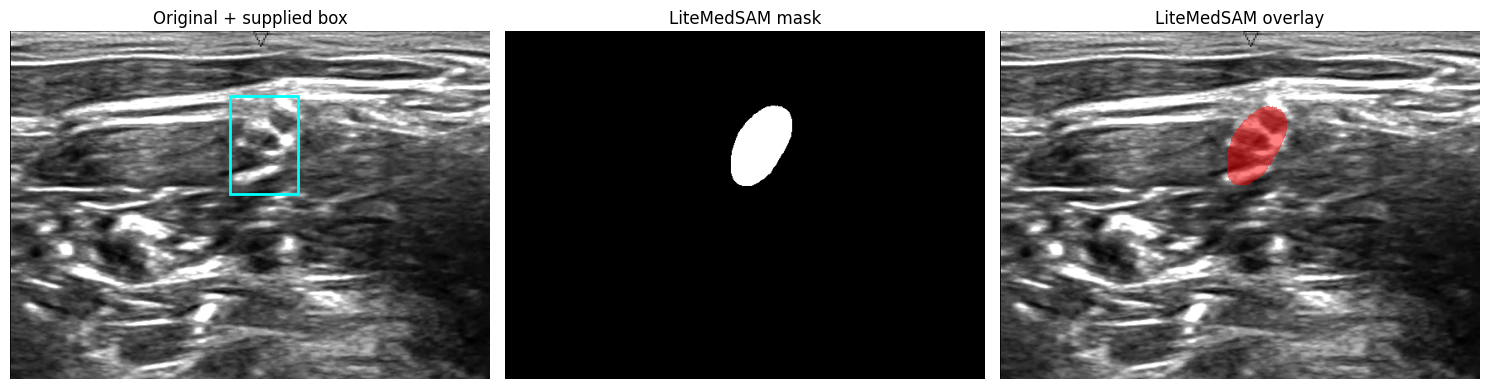

{
  "model": "LiteMedSAM",
  "encoder": "TinyViT",
  "device": "cpu",
  "runtime": {
    "python": "3.12.14 (main, Aug 25 2026, 13:50:33) [Clang 22.1.3 ]",
    "torch": "2.6.0",
    "cuda_build": null,
    "device": "cpu",
    "gpu": null
  },
  "sources": {
    "LiteMedSAM": {
      "original": "https://github.com/bowang-lab/MedSAM.git",
      "fork": "https://github.com/KrishnachaithanyaThummala/MedSAM.git",
      "branch": "LiteMedSAM",
      "commit": "b0fab476e54e631dd412b25e0db9fdf2a2b0f54c",
      "checked_out_commit": "b0fab476e54e631dd412b25e0db9fdf2a2b0f54c"
    },
    "MedNet": {
      "original": "https://github.com/Md-Ferdous/MedNet.git",
      "fork": "https://github.com/KrishnachaithanyaThummala/MedNet.git",
      "branch": "main",
      "commit": "6adb072630811b1d39568a87732aed96dc39c9ae",
      "checked_out_commit": "6adb072630811b1d39568a87732aed96dc39c9ae"
    }
  },
  "checkpoint_sha256": "79d8c9dca6db4d69d3f905579e5250af05e859fff9c1f543e89a513c3028ce76",
  "box_xyx

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
with stage("save_and_validate"):
    with np.load(RESULTS/SAMPLE.name,allow_pickle=False) as pred: labels=pred["segs"]
    assert labels.shape==image.shape[:2] and set(np.unique(labels)).issubset({0,1})
    mask=labels.astype(np.uint8)
    Image.fromarray(mask*255).save(RESULTS/"mask.png")
    Image.fromarray(image).save(RESULTS/"image.png")
    fig,axes=plt.subplots(1,3,figsize=(15,5))
    axes[0].imshow(image); axes[0].set_title("Original + supplied box")
    x0,y0,x1,y1=boxes[0]
    axes[0].add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,edgecolor="cyan",linewidth=2))
    axes[1].imshow(mask,cmap="gray",vmin=0,vmax=1); axes[1].set_title("LiteMedSAM mask")
    axes[2].imshow(image); axes[2].imshow(np.ma.masked_where(mask==0,mask),cmap="autumn",alpha=.5); axes[2].set_title("LiteMedSAM overlay")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.savefig(RESULTS/"summary.png",dpi=150); plt.show()
    report={"model":"LiteMedSAM","encoder":"TinyViT","device":DEVICE,"runtime":runtime,
            "sources":SOURCES,"checkpoint_sha256":actual_hash,"box_xyxy":boxes.tolist(),
            "mask_shape":list(mask.shape),"foreground_pixels":int(mask.sum()),"wall_seconds_includes_loading_io":wall_seconds,
            "pass_check":"PASS: image + valid supplied box -> saved mask", "original_model_source_modifications":[],
            "notebook_additions":["source/commit verification","runtime/dependency inventory","logging","display","output validation"],
            "interpretation":"Execution check only; not segmentation accuracy or diagnostic validation."}
    (RESULTS/"run.json").write_text(json.dumps(report,indent=2))
    print(json.dumps(report,indent=2))


**Result/inference:** The saved 420×580 mask completes Task 2's pass check. The foreground count is measured, not an accuracy metric. The box/mask/overlay must be inspected. There are no modifications to authors' tracked model files; this notebook adds setup, verification, logging and presentation only.

## 7. Package the results and evidence
Download the ZIP using Colab's Files pane: locate the archive printed below, right-click it and choose Download. Also save this notebook with its actual outputs. This avoids depending on a JavaScript-triggered download cell.

In [8]:
import shutil
BUNDLE=ROOT/"task12_evidence"; BUNDLE.mkdir(exist_ok=True)
shutil.copytree(RESULTS,BUNDLE/"results",dirs_exist_ok=True)
shutil.copytree(LOGS,BUNDLE/"logs",dirs_exist_ok=True)
archive=shutil.make_archive(str(ROOT/"LiteMedSAM_Tasks1_2_results"),"zip",root_dir=BUNDLE)
print("Evidence ZIP:",archive)
print("TASK 1: source checkouts + original URLs/branches/commits + inventory + package versions saved.")
print("TASK 2:",report["pass_check"],"on",DEVICE)


Evidence ZIP: /Users/krishnachaithanyathummala/Documents/ChatGPT/MEDSAM/outputs/tasks12_validation/LiteMedSAM_Tasks1_2_results.zip
TASK 1: source checkouts + original URLs/branches/commits + inventory + package versions saved.
TASK 2: PASS: image + valid supplied box -> saved mask on cpu


**Result/inference:** The ZIP contains the image, mask, prompt/provenance report, plot, inference log, stage errors if any, package versions and timing. Downloading to your computer is a separate action from creating the archive.

## What has and has not been changed
- Original LiteMedSAM and MedNet source files: unchanged; checked against pinned original Git commits.
- Added notebook: runtime selection, both fork checkouts, dependency installation, source inventory, source/checkpoint verification, logs, plots and saved evidence.
- MedNet: inspected/cloned only here; no training, classification forward pass or checkpoint claim is added to Tasks 1–2.
- Larger MedSAM: described for comparison, not executed here.

## Professor-facing explanation
"This notebook executes LiteMedSAM from its named branch, using TinyViT and the official lightweight checkpoint. It clones both requested implementations, records their provenance and installed versions, then uses the authors' original inference script on their ultrasound demo and supplied box. A saved binary mask demonstrates execution; it does not establish medical accuracy."